# Fuga por capitalización diaria: el valor de referencia de LiST de 12,11% a los 125 días

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema (la escalera, la NLP y el período de supervivencia)
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar la salida acumulada de una tasa diaria constante de fuga, $1-(1-q)^n$, y reproducir el valor de referencia de la prueba de tensión de liquidez del BCE (12,11% a los 125 días) con cada intermedio;
- invertirla, para convertir una corrida observada ("85% en 2 días") en la tasa diaria que la produce, y ver cuán lejos están entre sí las corridas de la Tabla A.1;
- construir día a día las salidas de un segmento, con el vencimiento contractual y la regla de no renovación de los depósitos financieros;
- contrastar una salida modelada con una corrida observada y leer la luz del semáforo.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Dos documentos versionados del caso C16 (el balance del banco que quebró el 2023-03-10: agregados reales del reporte de llamada de la FDIC, comportamiento y depósitos sintéticos, clase de licencia `mirror-allowed`):

- `data/derived/C16/list-adverse.json`: las salidas diarias de cada segmento de depósitos bajo la fuga del escenario Adverso de LiST 2019 del BCE, y la evaluación frente a la corrida de marzo de 2023.
- `data/derived/C16/lcr-standard.json`: las filas de prueba versionadas de las pruebas de fuga (el valor de referencia de LiST y la contrastación frente a las salidas del LCR a 30 días).

Las tasas de fuga son las Tablas 3.2 y 3.3 transcritas de la nota metodológica del BCE, que el motor guarda como datos del módulo (`LIST_PARAMETERS`); las corridas observadas son la Tabla A.1 del informe del BCBS sobre la turbulencia de 2023 (`TABLE_A1`).

In [2]:
# Cargar los dos documentos versionados (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
adverse = json.loads((ROOT / "data" / "derived" / "C16" / "list-adverse.json").read_text(encoding="utf-8"))
standard = json.loads((ROOT / "data" / "derived" / "C16" / "lcr-standard.json").read_text(encoding="utf-8"))
out = adverse["outputs"]

for name, doc in (("list-adverse", adverse), ("lcr-standard", standard)):
    print(name, "| calculado con riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

list-adverse | calculado con riskvalidation 0.9.0 | instalado 0.9.0
lcr-standard | calculado con riskvalidation 0.9.0 | instalado 0.9.0


## Método

### Paso 1: la salida acumulada de una tasa diaria constante

Los depósitos de vencimiento abierto de LiST (depósitos a la vista sin término contractual) se fugan a una tasa diaria constante $q$ capitalizada sobre el stock del día anterior, contada en días relevantes (BCE, 2019, nota metodológica, Tabla 3.3, párrafo 107). Tras $n$ días la proporción de salida acumulada es:

$$F(n) = 1 - (1 - q)^n$$

El valor de referencia es el ejemplo de la propia nota: los depósitos minoristas estables bajo el choque Adverso tienen $q = 0{,}103258\%$ por día relevante, y los seis meses tienen $n = 125$ días relevantes, lo que da $F(125) \approx 12{,}11\%$. La celda siguiente muestra los tres intermedios (la base $1-q$, su potencia y el complemento) y luego llama a `cumulative_outflow_constant`.

In [3]:
# El ejemplo dorado de la nota LiST: cada intermedio, y luego el motor
from riskvalidation.liquidity.runoff import LIST_PARAMETERS, cumulative_outflow_constant

q = LIST_PARAMETERS["adverse"]["open_maturity"]["stable-retail"]
n = 125
base = 1.0 - q
power = base ** n
by_hand = 1.0 - power
engine = cumulative_outflow_constant(q, n)

print("q =", q, "| n =", n)
print("1 - q =", round(base, 8))
print("(1 - q)^n =", round(power, 8))
print("1 - (1 - q)^n =", round(by_hand, 8))
print("motor:", round(engine, 8), "| igual:", ("sí" if np.isclose(by_hand, engine) else "no"))

q = 0.00103258 | n = 125
1 - q = 0.99896742
(1 - q)^n = 0.87885163
1 - (1 - q)^n = 0.12114837
motor: 0.12114837 | igual: sí


Esto es una verificación de la ecuación sobre un número, no una segunda implementación: la función del motor además valida sus entradas (una tasa en $[0,1]$, un número entero no negativo de días) y acepta arreglos. El producto envuelve el valor de referencia como una prueba de validación, `liq.list_compounding_golden`, cuyo estadístico es la distancia al valor impreso. La celda siguiente la llama y la pone junto a la fila versionada en `lcr-standard.json`, con la versión del motor que la calculó.

In [4]:
# El dorado como TestResult, y la fila versionada de la misma prueba
from riskvalidation.validation.liquidity import list_compounding_golden

golden = list_compounding_golden()
rows = {row["test_id"]: row for row in standard["tests"] if row["segment"] is None}
committed = rows["liq.list_compounding_golden"]

print("test_id:", golden.test_id)
print("salida acumulada:", round(golden.metric, 8), "| distancia al valor impreso:", golden.statistic, "| n =", golden.n)
print("semáforo:", golden.light.value, "| fila versionada:", committed["light"], "| calculada con", standard["provenance"]["riskvalidation_version"])
print("mismo estadístico que la fila versionada:", ("sí" if np.isclose(golden.statistic, committed["statistic"]) else "no"))

test_id: liq.list_compounding_golden
salida acumulada: 0.12114837 | distancia al valor impreso: 3.6571242759131373e-07 | n = 125
semáforo: green | fila versionada: green | calculada con 0.9.0
mismo estadístico que la fila versionada: sí


### Paso 2: la inversa, de una corrida observada a una tasa diaria

Una corrida observada se informa como una proporción $F$ de los depósitos perdida en $n$ días. La tasa diaria constante que se compone hasta ella es la inversa de la ecuación anterior:

$$q = 1 - (1 - F)^{1/n}$$

La Tabla A.1 del informe del BCBS sobre la turbulencia de 2023 (BCBS, 2023) lista nueve corridas, desde Northern Rock en 2007 hasta Silicon Valley Bank en 2023. El motor las guarda como `TABLE_A1` y calcula cada tasa implícita con `daily_rate_from_cumulative`. La revisión de la Reserva Federal sobre el banco (Federal Reserve, 2023) es la fuente del 85% en dos días. La celda siguiente lista las filas de la más lenta a la más rápida y comprueba el viaje de ida y vuelta.

In [5]:
# La tasa diaria implícita de cada corrida de la Tabla A.1, y el viaje de ida y vuelta por la ecuación directa
from riskvalidation.liquidity.runoff import TABLE_A1, daily_rate_from_cumulative

table = sorted(TABLE_A1, key=lambda r: r.implied_daily_rate)
print(f"{'banco':16s}{'año':>6s}{'salida':>10s}{'días':>6s}{'tasa diaria':>14s}{'ida y vuelta':>14s}")
for run in table:
    q_run = daily_rate_from_cumulative(run.outflow_share, run.days)
    back = cumulative_outflow_constant(q_run, run.days)
    print(f"{run.bank:16s}{run.year:6d}{run.outflow_share:10.2f}{run.days:6d}{q_run:14.6f}{back:14.6f}")

fastest, slowest = table[-1], table[0]
print("la más rápida sobre la más lenta:", round(fastest.implied_daily_rate / slowest.implied_daily_rate, 1))

banco              año    salida  días   tasa diaria  ida y vuelta
Credit Suisse     2023      0.21    90      0.002616      0.210000
Icesave           2008      0.20    75      0.002971      0.200000
IndyMac           2008      0.08    14      0.005938      0.080000
First Republic    2023      0.57    90      0.009334      0.570000
WaMu              2008      0.10    10      0.010481      0.100000
Northern Rock     2007      0.20     4      0.054258      0.200000
Signature         2023      0.20     1      0.200000      0.200000
SVB UK            2023      0.30     1      0.300000      0.300000
SVB               2023      0.85     2      0.612702      0.850000
la más rápida sobre la más lenta: 234.2


### Paso 3: las salidas de un segmento, día a día

Cuando la tasa cambia con el estado de la tensión, la salida acumulada es el producto de las supervivencias diarias, y la salida del día $d$ es el stock aún depositado por la tasa de ese día:

$$F(n) = 1 - \prod_{d \le n} (1 - q_d), \qquad O_s(d) = B_s \prod_{k < d} (1 - q_k)\; q_d$$

$B_s$ es el saldo inicial del segmento $s$. El motor tiene `cumulative_outflow_path` para la primera y `behavioural_outflows` para la segunda (multiplica la proporción de stock del día anterior por la tasa, de modo que nunca resta dos números casi iguales). La celda siguiente reconstruye el segmento minorista asegurado del documento a partir de su saldo inicial y sus 125 tasas diarias, e imprime los tres primeros días como intermedios.

In [6]:
# Reconstruir el segmento minorista asegurado desde su saldo inicial y sus tasas diarias, y comparar con el documento
from riskvalidation.liquidity.ladder import behavioural_outflows
from riskvalidation.liquidity.runoff import cumulative_outflow_path

segments = {s["segment"]: s for s in out["path"]["ladder"]["segments"]}
retail = segments["retail-insured"]
opening = np.array([retail["opening_balance"]])
rates = np.array([retail["daily_rates"]])
flows = behavioural_outflows(opening, rates)[0]
cumulative = cumulative_outflow_path(rates[0])

print("saldo inicial (miles de USD):", opening[0], "| días:", rates.shape[1], "| tasa diaria del día 1:", rates[0, 0])
survival = 1.0
for day in range(3):
    print(f"día {day + 1} | proporción aún depositada antes {survival:.8f} | tasa {rates[0, day]} | salida {opening[0] * survival * rates[0, day]:.4f} | motor {flows[day]:.4f}")
    survival *= 1.0 - rates[0, day]
print("mismas salidas que el documento:", ("sí" if np.allclose(flows, retail["outflows"]) else "no"))
print("misma proporción acumulada:", ("sí" if np.allclose(cumulative, retail["cumulative_outflow_share"]) else "no"), "|", round(cumulative[-1], 6))
print("las salidas suman saldo inicial x proporción acumulada:", ("sí" if np.isclose(flows.sum(), opening[0] * cumulative[-1]) else "no"))

saldo inicial (miles de USD): 9990000.0 | días: 125 | tasa diaria del día 1: 0.00373218
día 1 | proporción aún depositada antes 1.00000000 | tasa 0.00373218 | salida 37284.4782 | motor 37284.4782
día 2 | proporción aún depositada antes 0.99626782 | tasa 0.00373218 | salida 37145.3258 | motor 37145.3258
día 3 | proporción aún depositada antes 0.99254957 | tasa 0.00373218 | salida 37006.6928 | motor 37006.6928
mismas salidas que el documento: sí
misma proporción acumulada: sí | 0.373368
las salidas suman saldo inicial x proporción acumulada: sí


Las mismas dos funciones aceptan una tasa que cambia. Como exploración, no como escenario versionado, la celda siguiente duplica la tasa de este segmento del día 11 al día 20 y compara la salida acumulada al día 125 con el caso constante: importa la trayectoria, no solo la tasa media.

In [7]:
# Una tasa que se duplica en los días 11 a 20 (una exploración, no un escenario versionado)
what_if = rates[0].copy()
what_if[10:20] *= 2.0
path_what_if = cumulative_outflow_path(what_if)

print("salida acumulada al día 125, tasa constante:", round(cumulative[-1], 6))
print("salida acumulada al día 125, duplicada del día 11 al 20:", round(path_what_if[-1], 6))
print("salida adicional (miles de USD):", round(opening[0] * (path_what_if[-1] - cumulative[-1]), 2))

salida acumulada al día 125, tasa constante: 0.373368
salida acumulada al día 125, duplicada del día 11 al 20: 0.39645
salida adicional (miles de USD): 230597.75


### Paso 4: el vencimiento contractual y los depósitos financieros

No todo pasivo es de vencimiento abierto. Un pasivo contractual sale del balance cuando vence, y LiST aplica a cada flujo que vence una tasa de salida constante por clase (Tabla 3.2, párrafo 94); el resto se supone renovado y queda más allá del horizonte. Los depósitos interbancarios y otros financieros que vencen no se renuevan en absoluto (párrafo 98, tasa 1). El motor tiene `contractual_rolloff` y `financial_no_rollover`; los depósitos a la vista de clientes financieros salen completos el primer día relevante (párrafo 111), que es como el documento corre su segmento `financial`. La celda siguiente muestra las tres reglas.

In [8]:
# Salida contractual de un flujo que vence, la regla sin renovación y el segmento financiero del documento
from riskvalidation.liquidity.runoff import contractual_rolloff, financial_no_rollover

maturing = np.array([100.0, 50.0])
contractual = LIST_PARAMETERS["adverse"]["contractual_outflow"]
print("tasas de salida contractual, Adverso:", {k: contractual[k] for k in ("stable-retail", "other-retail", "non-operational-credit-institutions")})
print("un flujo de [100, 50] que vence, minorista estable:", contractual_rolloff(maturing, contractual["stable-retail"]))
print("el mismo flujo, un depósito financiero:", financial_no_rollover(maturing))

financial = segments["financial"]
horizon = len(financial["outflows"])
full = behavioural_outflows(np.array([financial["opening_balance"]]), np.ones((1, horizon)))[0]
print("segmento financiero, tasa 1 todos los días:", full[:3], "| igual que el documento:", ("sí" if np.allclose(full, financial["outflows"]) else "no"))

tasas de salida contractual, Adverso: {'stable-retail': 0.18, 'other-retail': 0.39, 'non-operational-credit-institutions': 1.0}
un flujo de [100, 50] que vence, minorista estable: [18.  9.]
el mismo flujo, un depósito financiero: [100.  50.]
segmento financiero, tasa 1 todos los días: [13899000.        0.        0.] | igual que el documento: sí


### Paso 5: la contrastación con una corrida observada

Un supuesto de fuga puede contrastarse con lo ocurrido. La prueba `liq.runoff_adequacy_back_test` compara la proporción de salida modelada con la realizada (los supuestos de Basilea frente a la tasa observada):

$$\text{ratio} = \frac{\text{modelled share}}{\text{realised share}}, \qquad \text{shortfall} = \text{realised share} - \text{modelled share}$$

Es un puntaje descriptivo sobre un evento real, sin valor p. El semáforo es una compuerta interna de Contraste (verde desde una razón de 0,8, ámbar desde 0,5, rojo por debajo), no un umbral regulatorio. La proporción realizada es el "cerca de 85 por ciento" de la base de depósitos en dos días de la Reserva Federal (Federal Reserve, 2023); la proporción modelada es la suma de los dos primeros días de las salidas por segmento del documento sobre la base de depósitos del modelo. La celda siguiente calcula la proporción modelada y llama a la prueba.

In [9]:
# Contrastar los dos primeros días de las salidas LiST Adverso con el 85 por ciento observado en dos días
from riskvalidation.validation.liquidity import runoff_adequacy_back_test

scoring = out["scoring"]
base_deposits = scoring["model_deposit_base"]
first_two_days = sum(sum(s["outflows"][:2]) for s in out["path"]["ladder"]["segments"])
modelled = first_two_days / base_deposits
board = scoring["denominators"][0]

test = runoff_adequacy_back_test(modelled, board["realised_share"], compared_at="event-horizon", denominator=board["id"])
committed_rows = [row for row in adverse["tests"] if row["test_id"] == "liq.runoff_adequacy_back_test" and row["segment"] == board["id"]]

print("salida de los dos primeros días (miles de USD):", round(first_two_days, 2), "| base de depósitos del modelo:", base_deposits)
print("proporción modelada:", round(modelled, 6), "| proporción realizada:", board["realised_share"])
print("razón:", round(test.statistic, 6), "| déficit:", round(test.metric, 6), "| semáforo:", test.light.value)
print("fila versionada:", round(committed_rows[0]["statistic"], 6), committed_rows[0]["light"], "| misma razón:", ("sí" if np.isclose(test.statistic, committed_rows[0]["statistic"]) else "no"))
compared = {"event-horizon": "horizonte del evento", "model-horizon": "horizonte del modelo (30 días)"}
for row in standard["tests"]:
    if row["test_id"] == "liq.runoff_adequacy_back_test":
        print("lcr-standard |", row["segment"], "|", compared[row["policy_version"].split("compared_at=")[1]], "|", round(row["statistic"], 6), row["light"])

salida de los dos primeros días (miles de USD): 16053789.14 | base de depósitos del modelo: 175481000.0
proporción modelada: 0.091484 | proporción realizada: 0.85
razón: 0.107629 | déficit: 0.758516 | semáforo: red
fila versionada: 0.107629 red | misma razón: sí
lcr-standard | board-stated-share | horizonte del modelo (30 días) | 0.506405 amber
lcr-standard | call-report-dep | horizonte del modelo (30 días) | 0.539534 amber


La última celda dibuja la lección central del cuaderno. Las curvas suaves son las salidas acumuladas de LiST Adverso de tres clases en 125 días; los puntos son las nueve corridas de la Tabla A.1 en su propio horizonte. Toda curva suave queda bajo cuatro de las cinco corridas de 2023 (SVB, SVB UK, Signature y First Republic); solo la corrida de Credit Suisse, de 90 días, queda bajo las dos curvas más rápidas. Las tasas de la prueba de tensión describen una fuga lenta, las corridas rápidas de 2023 describen otra cosa.

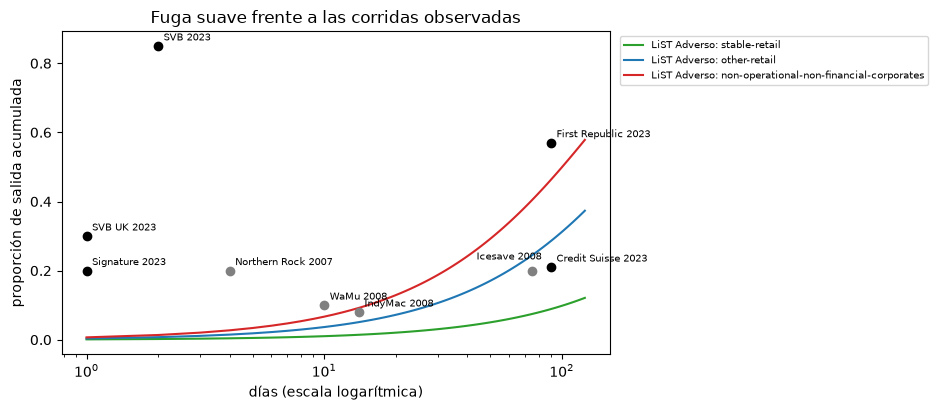

In [10]:
# Dibujar las curvas suaves LiST Adverso contra las corridas de la Tabla A.1
fig, ax = plt.subplots(figsize=(9.5, 4.2))
days = np.arange(1, 126)
for name, color in (("stable-retail", "tab:green"), ("other-retail", "tab:blue"), ("non-operational-non-financial-corporates", "tab:red")):
    ax.plot(days, cumulative_outflow_constant(LIST_PARAMETERS["adverse"]["open_maturity"][name], days), color=color, label=f"LiST Adverso: {name}")
for run in TABLE_A1:
    ax.scatter(run.days, run.outflow_share, color="black" if run.year == 2023 else "gray", zorder=3)
    ax.annotate(f"{run.bank} {run.year}", (run.days, run.outflow_share), textcoords="offset points", xytext=(-40, 8) if run.row_id == "icesave-2008" else (4, 4), fontsize=7)
ax.set_xscale("log")
ax.set_xlabel("días (escala logarítmica)")
ax.set_ylabel("proporción de salida acumulada")
ax.set_title("Fuga suave frente a las corridas observadas")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
plt.show()

## Resultados

- **El valor de referencia.** La base, su potencia 125 y el complemento son 0,99896742, 0,87885163 y 0,12114837, y el motor coincide. La prueba de referencia del producto es verde, a cerca de 3,7e-07 del 12,11% impreso, y su estadístico es igual al versionado en `lcr-standard.json`.
- **La inversa.** La tasa diaria implícita de las nueve corridas va de 0,002616 (Credit Suisse, 21% en 90 días) a 0,612702 (SVB, 85% en 2 días): la más rápida es 234,2 veces la más lenta, y cada tasa devuelve la proporción de la tabla en el viaje de ida y vuelta. La tasa minorista estable de la nota, 0,00103258, es menor que la de la corrida más lenta de la tabla.
- **El segmento.** El segmento minorista asegurado pierde 37.284,48 miles de USD el día 1 y 37.145,33 el día 2 (el stock se achica, la tasa no) y 0,373368 de su stock a los 125 días; el motor y el documento coinciden en la serie y en la proporción acumulada, y las salidas suman el saldo inicial por esa proporción. Duplicar la tasa en los días 11 a 20 sube la salida acumulada de 0,373368 a 0,39645, es decir, 230.597,75 miles de USD más. Un flujo contractual de [100, 50] de minorista estable vence como [18, 9], el mismo flujo de un depósito financiero sale completo, y el segmento financiero del documento sale con 13.899.000 miles de USD el día 1.
- **La contrastación.** La salida de LiST Adverso de los dos primeros días es 16.053.789,14 miles de USD, 0,091484 de la base de depósitos del modelo. Frente al 0,85 de la Reserva Federal esto es una razón de 0,107629 y un déficit de 0,758516, rojo bajo las compuertas internas; el motor y la fila versionada coinciden. Frente a las salidas del LCR a 30 días (el horizonte del modelo) las dos filas versionadas son ámbar, con razones de 0,506405 y 0,539534. El supuesto suave está lejos del evento que debe cubrir; las filas describen un evento real con depósitos sintéticos, una observación y ningún valor p, así que muestran el tamaño de la brecha, no una probabilidad.

Lo que este cuaderno no muestra: cómo se construye el CBC frente al que se ponen estas salidas (cuaderno 03), cómo se componen los segmentos en un escenario (cuaderno 04) o qué dice el LCR (cuaderno 05).

## Resumen

- Una tasa diaria constante $q$ se compone hasta $1-(1-q)^n$ tras $n$ días; el valor de referencia de LiST (12,11% a los 125 días con 0,103258% diario) se reproduce con la precisión impresa.
- Su inversa convierte cualquier corrida observada en una tasa diaria, lo que pone corridas muy distintas en una misma escala.
- Las salidas de un segmento son el stock aún depositado por la tasa diaria; los pasivos contractuales vencen por clase y los depósitos financieros no se renuevan.
- Una contrastación pone la salida modelada frente a una corrida observada; bajo las compuertas internas del producto la salida de LiST Adverso de los dos primeros días es roja frente al 85% de marzo de 2023.

**Qué probar a continuación.** Cambia el día y la tasa de la exploración (una duplicación en los días 1 a 5) y mira cuánto de la salida acumulada viene de la primera semana; luego sigue con el cuaderno 03.

## Referencias

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06), Tables 3.2 and 3.3 and paragraphs 94, 98, 107 and 111. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm
- Federal Reserve Board (2023-04-28), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf